KMSY--KBHM extended-transect geometry
  KMSY -> KBHM bearing: 39.08 degrees toward
  Meteorological from direction: 219.08 degrees
  KMSY -> KBHM distance: 516.49 km
  Extended start: 29.291451, -90.906729
  Extended end: 32.399006, -87.937059
  Total extended distance: 446.49 km
Processing wrfout_d03_1998-02-22_13:00:00


/glade/derecho/scratch/rbhandari/tmp/ipykernel_68369/1052661894.py:1130: UserWarning: The following kwargs were not used by contour: 'rasterized'
  filled_w = ax_left.contourf(
/glade/derecho/scratch/rbhandari/tmp/ipykernel_68369/1052661894.py:1304: UserWarning: The following kwargs were not used by contour: 'rasterized'
  filled_wind_speed = ax_right.contourf(
/glade/derecho/scratch/rbhandari/tmp/ipykernel_68369/1052661894.py:1354: UserWarning: The following kwargs were not used by contour: 'rasterized'
  ax_right.contourf(


  Dynamic 0--10-km color ranges: w = -1.346 to 1.517 m s-1; wind speed = 5.48 to 54.26 m s-1 (fill capped at 65 m s-1)


/glade/u/apps/opt/conda/envs/npl-2024a/lib/python3.11/site-packages/cartopy/mpl/geoaxes.py:1655: UserWarning: The following kwargs were not used by contour: 'rasterized'
  result = super().contourf(*args, **kwargs)


Processing wrfout_d03_1998-02-22_13:45:00


/glade/derecho/scratch/rbhandari/tmp/ipykernel_68369/1052661894.py:1130: UserWarning: The following kwargs were not used by contour: 'rasterized'
  filled_w = ax_left.contourf(
/glade/derecho/scratch/rbhandari/tmp/ipykernel_68369/1052661894.py:1304: UserWarning: The following kwargs were not used by contour: 'rasterized'
  filled_wind_speed = ax_right.contourf(
/glade/derecho/scratch/rbhandari/tmp/ipykernel_68369/1052661894.py:1354: UserWarning: The following kwargs were not used by contour: 'rasterized'
  ax_right.contourf(


... (7 outputs left out)

/glade/derecho/scratch/rbhandari/tmp/ipykernel_68369/1052661894.py:1130: UserWarning: The following kwargs were not used by contour: 'rasterized'
  filled_w = ax_left.contourf(
/glade/derecho/scratch/rbhandari/tmp/ipykernel_68369/1052661894.py:1304: UserWarning: The following kwargs were not used by contour: 'rasterized'
  filled_wind_speed = ax_right.contourf(
/glade/derecho/scratch/rbhandari/tmp/ipykernel_68369/1052661894.py:1354: UserWarning: The following kwargs were not used by contour: 'rasterized'
  ax_right.contourf(


  Dynamic 0--10-km color ranges: w = -2.032 to 1.862 m s-1; wind speed = 4.77 to 55.62 m s-1 (fill capped at 65 m s-1)


/glade/u/apps/opt/conda/envs/npl-2024a/lib/python3.11/site-packages/cartopy/mpl/geoaxes.py:1655: UserWarning: The following kwargs were not used by contour: 'rasterized'
  result = super().contourf(*args, **kwargs)


Saved /glade/u/home/rbhandari/Alabama-MP-8-1min/Final-publication-plots/Github/KMSY_KBHM_STORMFEST_cross_sections_130000_134500_144500_153500UTC_combined.png
Saved /glade/u/home/rbhandari/Alabama-MP-8-1min/Final-publication-plots/Github/KMSY_KBHM_STORMFEST_cross_sections_130000_134500_144500_153500UTC_combined.pdf


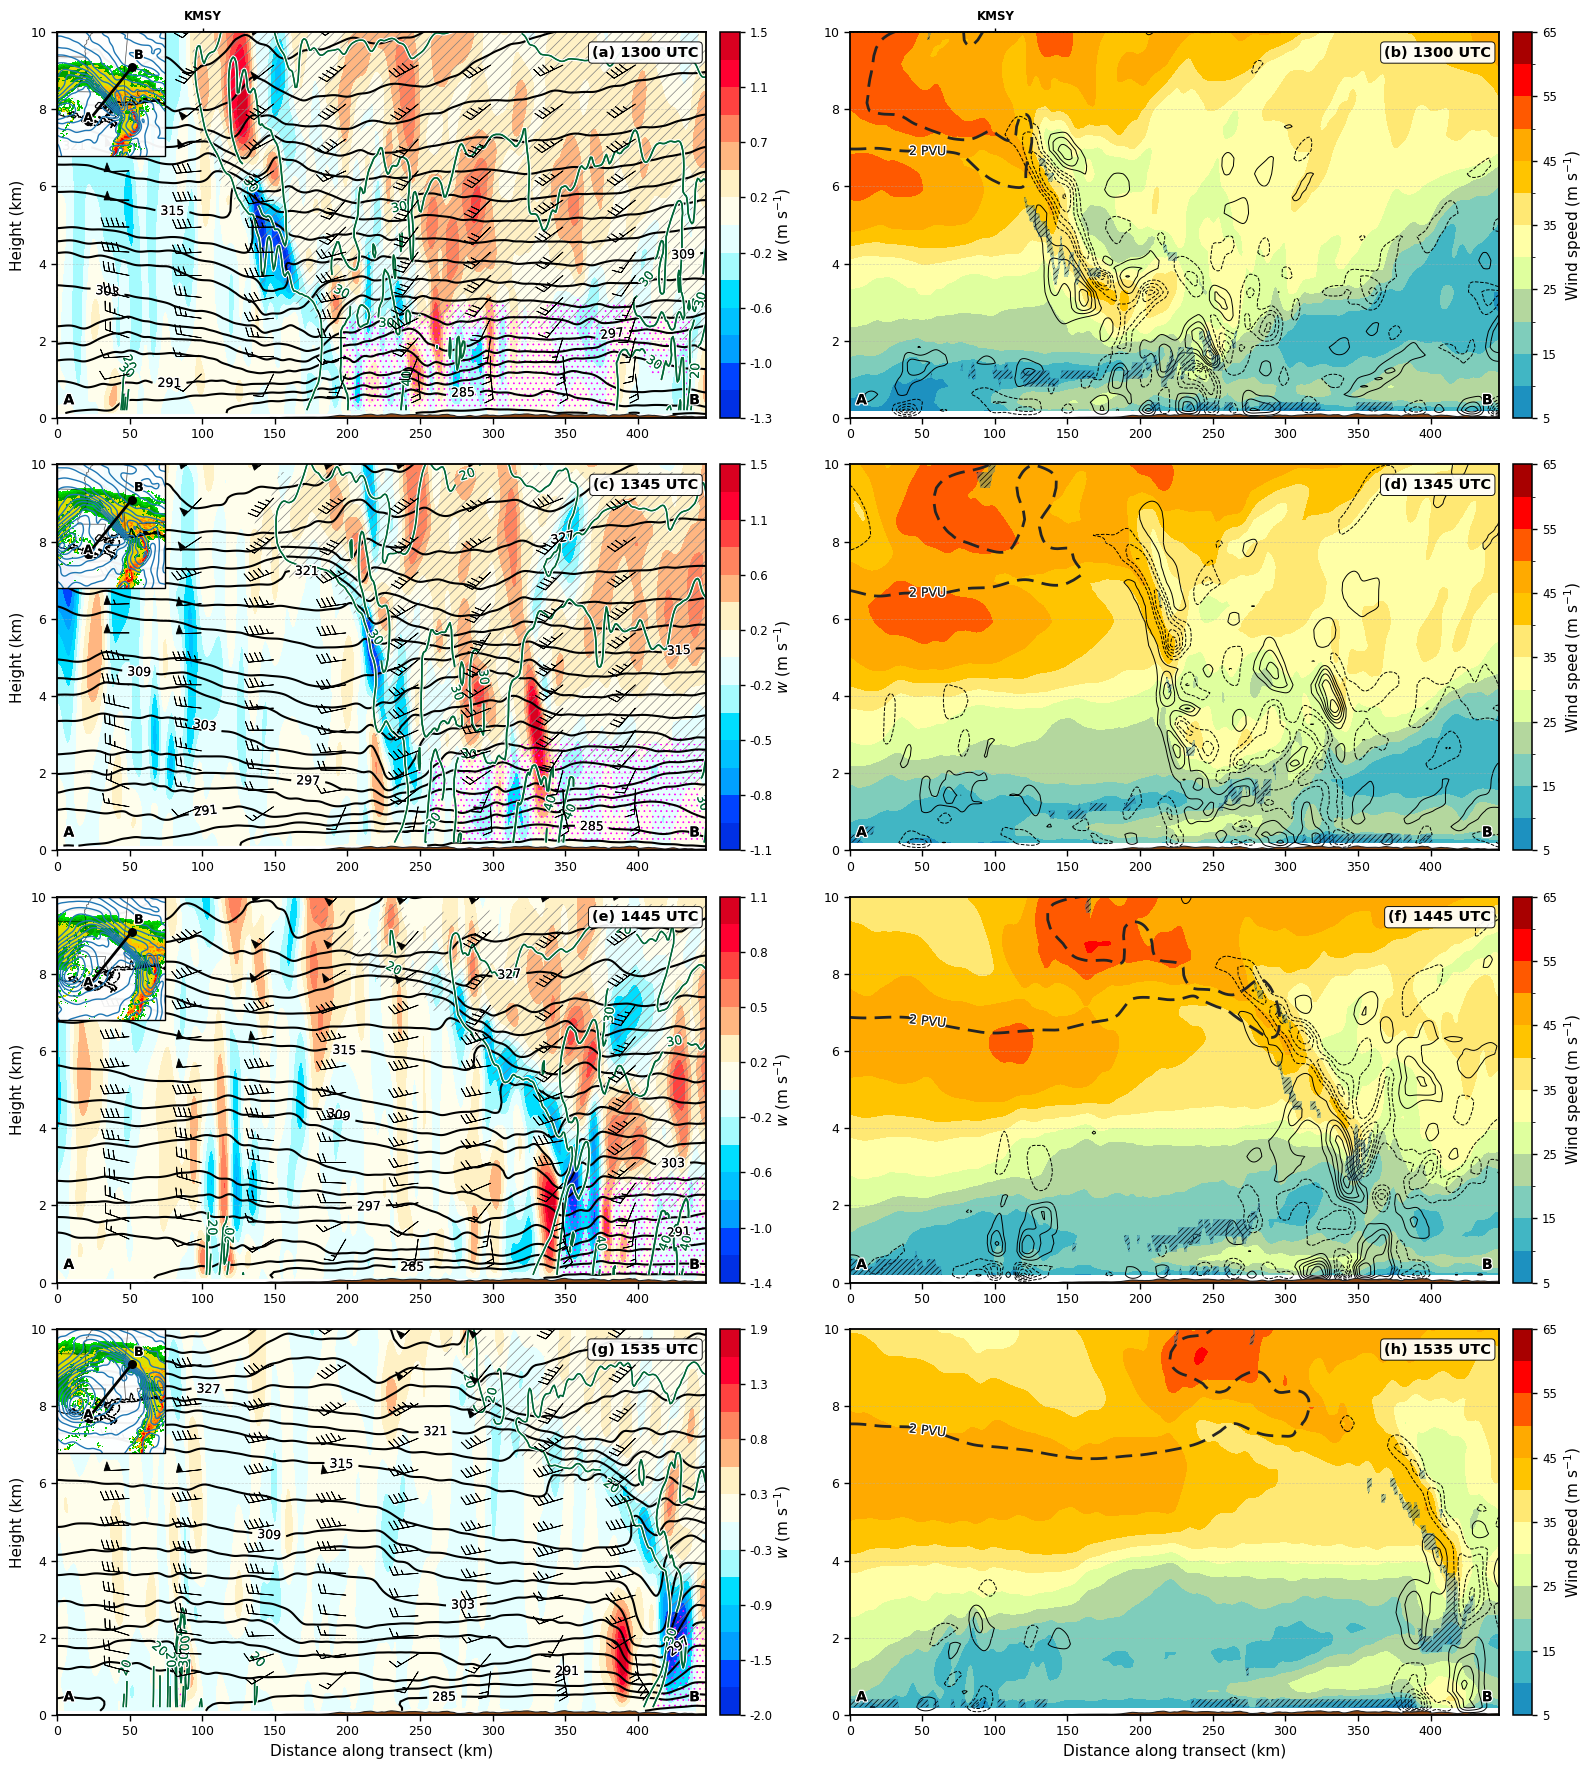

Completed one combined four-time figure.


In [1]:
from datetime import datetime, timezone
from pathlib import Path
import warnings

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
from matplotlib.colors import (
    BoundaryNorm,
    ListedColormap,
    Normalize,
    TwoSlopeNorm,
)
import metpy.calc as mpcalc
from metpy.units import units
from netCDF4 import Dataset
import numpy as np
from pyproj import Geod
from scipy.ndimage import gaussian_filter, gaussian_filter1d
from wrf import (
    CoordPair,
    get_cartopy,
    getvar,
    interpline,
    latlon_coords,
    to_np,
    vertcross,
)

# Thresholds for the snow and rain overlays on the left panels (g/kg).
QSNOW_THRESHOLD_GKG = 0.15
QRAIN_THRESHOLD_GKG = 0.15

dataDir = Path(
    "/glade/derecho/scratch/rbhandari/AL-CNTRL-MP8-LH/"
    "wrfv4.7.1/test/em_real"
)
# d01, d02 or d03.
DOMAIN = "d03"
CASE_DATE = datetime(1998, 2, 22, tzinfo=timezone.utc)
# Four valid times as (hour, minute, second), one per figure row.
TIMES_UTC = [
    (13, 00, 0),
    (13, 45, 0),
    (14, 45, 0),
    (15, 35, 0),
]
TIME_TAG = "_".join(
    f"{hour:02d}{minute:02d}{second:02d}"
    for hour, minute, second in TIMES_UTC
)
# Vertical extent of the cross sections.
PLOT_TOP_KM = 10.0
PLOT_TOP_M = PLOT_TOP_KM * 1000.0
VERTICAL_TICK_INTERVAL_KM = 2.0

# Theta contours.
THETA_CONTOUR_LINESTYLE = "solid"
THETA_CONTOUR_LINEWIDTH = 1.5
# Interval in K; label every other contour.
THETA_INTERVAL_K = 3.0
THETA_LABEL_EVERY = 2

# Letters run row-wise: (a),(b) then (c),(d) and so on.
PANEL_LETTERS = "abcdefgh"
PANEL_LABEL_FONTSIZE = 10.5

# Smoothing. Sigmas are in grid points. Cross sections are smoothed along the
# transect only, except PV, which gets its own vertical and horizontal sigmas.
# SLP is a map field, so its sigma acts in both directions.
SLP_MAP_SMOOTH_SIGMA = 15
THETA_HORIZONTAL_SMOOTH_SIGMA = 3
W_HORIZONTAL_SMOOTH_SIGMA = 3
# Wind-speed fill only. 0 turns the smoothing off.
WSPD_HORIZONTAL_SMOOTH_SIGMA = 2.0
Z_HORIZONTAL_SMOOTH_SIGMA = 0.1
MFD_HORIZONTAL_SMOOTH_SIGMA = 5
RI_HORIZONTAL_SMOOTH_SIGMA = 0.001
PV_VERTICAL_SMOOTH_SIGMA = 1.0
PV_HORIZONTAL_SMOOTH_SIGMA = 8

# Wind barbs.
BARB_LENGTH = 6.0
BARB_LW = 0.6
BARB_SIZES = dict(emptybarb=0.08, spacing=0.20, height=0.35)
BARB_INCS = dict(half=5, full=10, flag=50)
MIN_BARB_Z_KM = 1.0
# One barb every N points along the transect.
BARB_HORIZONTAL_SKIP = 50
# Rows of the interpolated cross section, not WRF eta levels.
BARB_VERTICAL_START_INDEX = 2
BARB_VERTICAL_SPLIT_INDEX = 14
BARB_VERTICAL_LOWER_SKIP = 6
BARB_VERTICAL_UPPER_SKIP = 5

# Write output wherever the script is run from.
OUTPUT_DIR = Path.cwd()
SAVE_DPI = 600
# Sized so the four rows fit a full manuscript page.
FIGURE_SIZE = (16.0, 18.0)

# Panel borders, ticks and colorbar outlines.
FRAME_COLOR = "black"
PANEL_SPINE_WIDTH = 1.3
INSET_SPINE_WIDTH = 1.0
COLORBAR_OUTLINE_WIDTH = 1.1
TICK_MAJOR_WIDTH = 1.0
TICK_MAJOR_LENGTH = 4.0

# Dark green reads against both the red updraft and blue downdraft shading.
REFLECTIVITY_CONTOUR_COLOR = "#006837"

# Halo behind lines and labels so they stay legible over the fill.
HALO_LINE = [pe.withStroke(linewidth=2.8, foreground="white"), pe.Normal()]
HALO_TEXT = [pe.withStroke(linewidth=2.0, foreground="white"), pe.Normal()]

# False for batch runs.
SHOW_EACH_FIGURE = True

# Airports, (lat, lon) in degrees.
KMSY = (29.9934, -90.2580)  # Louis Armstrong New Orleans International Airport
KBHM = (33.5629, -86.7535)  # Birmingham-Shuttlesworth International Airport
EXTEND_BEFORE_KMSY_KM = 100.0
EXTEND_BEYOND_KBHM_KM = -170.0
# A station is labelled only if it lies this close to the transect.
MAX_OFFTRACK_KM = 40.0

# Plot defaults.
plt.rcParams.update(
    {
        "font.size": 11,
        "axes.labelsize": 11,
        "axes.titlesize": 11,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
        "font.weight": "normal",
        "savefig.dpi": SAVE_DPI,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        # Heavier frames.
        "axes.linewidth": PANEL_SPINE_WIDTH,
        "axes.edgecolor": FRAME_COLOR,
        "xtick.color": FRAME_COLOR,
        "ytick.color": FRAME_COLOR,
        "xtick.major.width": TICK_MAJOR_WIDTH,
        "ytick.major.width": TICK_MAJOR_WIDTH,
        "xtick.major.size": TICK_MAJOR_LENGTH,
        "ytick.major.size": TICK_MAJOR_LENGTH,
        "xtick.direction": "out",
        "ytick.direction": "out",
        "hatch.linewidth": 0.5,
    }
)
# Vertical velocity: seven cool colors down, seven warm up. Levels are set
# per valid time from the plotted w range, split at zero. There are no
# over/under colors, so w is clipped into range and the colorbar ends flat.
W_COLORS = [
    "#0030E5",
    "#0043FF",
    "#01A0FF",
    "#00C2FF",
    "#00DEFF",
    "#A5FBFE",
    "#E5FFFF",
    "#FFFEEC",
    "#FFF1C5",
    "#FFB681",
    "#FF845F",
    "#FF4240",
    "#FF0031",
    "#D90020",
]
W_CMAP = ListedColormap(W_COLORS, name="custom_vertical_velocity")
W_N_LEVELS = len(W_COLORS) + 1
W_N_SIDE_COLORS = len(W_COLORS) // 2
W_CBAR_TICK_STEP = 2

# Wind speed in 5 m s^-1 steps from 5 to 65. Below 5 is left unfilled and
# anything above 65 is clipped into the top bin.
WSPD_COLORS = [
    "#1D91C0",  #  5--10 m s^-1
    "#41B6C4",  # 10--15 m s^-1
    "#7FCDBB",  # 15--20 m s^-1
    "#B4D79E",  # 20--25 m s^-1
    "#DFFF9E",  # 25--30 m s^-1
    "#FFFFA6",  # 30--35 m s^-1
    "#FFE873",  # 35--40 m s^-1
    "#FFC400",  # 40--45 m s^-1
    "#FFAA00",  # 45--50 m s^-1
    "#FF5900",  # 50--55 m s^-1
    "#FF0000",  # 55--60 m s^-1
    "#A80000",  # 60--65 m s^-1
]
WSPD_LEVELS = np.arange(5.0, 66.0, 5.0)  # 5, 10, ..., 65
WSPD_MAX = float(WSPD_LEVELS[-1])
WSPD_CMAP = ListedColormap(WSPD_COLORS, name="custom_wind_speed")
WSPD_NORM = BoundaryNorm(WSPD_LEVELS, WSPD_CMAP.N, clip=False)
WSPD_CBAR_TICKS = WSPD_LEVELS[::2]  # 5, 15, 25, ..., 65
WSPD_ALPHA = 1.00
# Reflectivity, shared by the cross sections and the inset map.
REFLECTIVITY_LEVELS = np.arange(20.0, 85.0, 5.0)
REFLECTIVITY_COLORS = [
    "#00e000",  # 20--25 dBZ: bright green
    "#00c000",  # 25--30 dBZ: green
    "#00a000",  # 30--35 dBZ: dark green
    "#e0e000",  # 35--40 dBZ: yellow
    "#ffc000",  # 40--45 dBZ: golden yellow
    "#ff9000",  # 45--50 dBZ: orange
    "#ff6000",  # 50--55 dBZ: red-orange
    "#ff0000",  # 55--60 dBZ: bright red
    "#d00000",  # 60--65 dBZ: dark red
    "#a000a0",  # 65--70 dBZ: purple
    "#a000c0",  # 70--75 dBZ: violet
    "#a000e0",  # 75--80+ dBZ: bright purple
]
PV_CONTOUR_PVU = 2.0
PV_CONTOUR_COLOR = "#242424"
PV_CONTOUR_LABEL_COLOR = "#242424"
PV_CONTOUR_LINEWIDTH = 2.0
PV_CONTOUR_LINESTYLE = (0, (6, 3))
PV_CONTOUR_LABEL_SIZE = 9

# Helpers.
WGS84 = Geod(ellps="WGS84")


def style_panel_frame(axis, spine_width=PANEL_SPINE_WIDTH):
    """Dark, uniform spines and matching ticks."""
    for spine in axis.spines.values():
        spine.set_edgecolor(FRAME_COLOR)
        spine.set_linewidth(spine_width)
        # Above the terrain fill and the barbs, which would otherwise
        # paint over the bottom spine.
        spine.set_zorder(20)
    axis.tick_params(
        which="major",
        color=FRAME_COLOR,
        width=TICK_MAJOR_WIDTH,
        length=TICK_MAJOR_LENGTH,
    )


def style_colorbar_frame(colorbar):
    """Dark outline and ticks for a colorbar (flat ends, no triangles)."""
    colorbar.outline.set_edgecolor(FRAME_COLOR)
    colorbar.outline.set_linewidth(COLORBAR_OUTLINE_WIDTH)
    colorbar.ax.tick_params(
        which="major",
        color=FRAME_COLOR,
        width=TICK_MAJOR_WIDTH,
        length=3.5,
    )
    colorbar.ax.minorticks_off()


def apply_contour_path_effects(contour_set, effects):
    """Attach path effects to a ContourSet across matplotlib versions."""
    try:
        contour_set.set_path_effects(effects)
    except AttributeError:
        for collection in contour_set.collections:
            collection.set_path_effects(effects)


def apply_label_path_effects(label_texts, effects):
    """Attach path effects to every clabel text object."""
    for label_text in label_texts:
        label_text.set_path_effects(effects)


def _point_at_arclength(line_xy, cumulative_px, target_arclength_px):

    target_arclength_px = float(
        np.clip(target_arclength_px, cumulative_px[0], cumulative_px[-1])
    )
    segment_index = int(np.searchsorted(cumulative_px, target_arclength_px)) - 1
    segment_index = int(np.clip(segment_index, 0, len(cumulative_px) - 2))
    segment_length_px = (
        cumulative_px[segment_index + 1] - cumulative_px[segment_index]
    )
    if segment_length_px <= 0:
        fraction = 0.0
    else:
        fraction = (
            target_arclength_px - cumulative_px[segment_index]
        ) / segment_length_px
    point = line_xy[segment_index] + fraction * (
        line_xy[segment_index + 1] - line_xy[segment_index]
    )
    return point, segment_index


def draw_line_with_inline_label(
    ax,
    line_xy,
    label_text,
    label_index,
    color,
    linestyle,
    linewidth,
    fontsize,
    text_effects,
    gap_px=34.0,
    zorder=4,
):

    line_xy = np.asarray(line_xy, dtype=float)
    n_points = line_xy.shape[0]
    if n_points < 2:
        return
    label_index = int(np.clip(label_index, 0, n_points - 1))
    display_xy = ax.transData.transform(line_xy)
    segment_lengths_px = np.hypot(
        np.diff(display_xy[:, 0]), np.diff(display_xy[:, 1])
    )
    cumulative_px = np.concatenate(([0.0], np.cumsum(segment_lengths_px)))
    total_length_px = float(cumulative_px[-1])
    label_arclength_px = float(cumulative_px[label_index])
    # Do not open a gap wider than the line, so short branches still draw.
    half_gap_px = min(gap_px / 2.0, 0.45 * total_length_px)
    gap_start_point, _ = _point_at_arclength(
        line_xy, cumulative_px, label_arclength_px - half_gap_px
    )
    gap_end_point, gap_end_segment_index = _point_at_arclength(
        line_xy, cumulative_px, label_arclength_px + half_gap_px
    )
    # Rotate the label to follow the line it interrupts.
    disp_gap_start = ax.transData.transform(gap_start_point)
    disp_gap_end = ax.transData.transform(gap_end_point)
    angle_deg = np.degrees(
        np.arctan2(
            disp_gap_end[1] - disp_gap_start[1],
            disp_gap_end[0] - disp_gap_start[0],
        )
    )
    # Keep it upright.
    if angle_deg > 90.0:
        angle_deg -= 180.0
    elif angle_deg < -90.0:
        angle_deg += 180.0
    before_start_arclength = label_arclength_px - half_gap_px
    before_last_index = int(
        np.searchsorted(cumulative_px, before_start_arclength)
    )
    before_last_index = int(np.clip(before_last_index, 0, label_index))
    before_segment = np.vstack(
        [line_xy[: before_last_index + 1], gap_start_point]
    )
    after_segment = np.vstack(
        [gap_end_point, line_xy[gap_end_segment_index + 1 :]]
    )
    for segment in (before_segment, after_segment):
        if segment.shape[0] >= 2:
            ax.plot(
                segment[:, 0],
                segment[:, 1],
                color=color,
                linestyle=linestyle,
                linewidth=linewidth,
                zorder=zorder,
            )
    label_midpoint = (gap_start_point + gap_end_point) / 2.0
    label = ax.text(
        label_midpoint[0],
        label_midpoint[1],
        label_text,
        color=color,
        fontsize=fontsize,
        ha="center",
        va="center",
        rotation=angle_deg,
        rotation_mode="anchor",
        zorder=zorder + 2,
    )
    label.set_path_effects(text_effects)


def build_extended_transect():
    """Return the extended KMSY--KBHM WGS84 transect."""
    kmsy_lat, kmsy_lon = KMSY
    kbhm_lat, kbhm_lon = KBHM
    az_kmsy_to_kbhm, az_kbhm_to_kmsy, center_distance_m = WGS84.inv(
        kmsy_lon, kmsy_lat, kbhm_lon, kbhm_lat
    )
    # Go backward from KMSY along the same geodesic.
    start_azimuth = (az_kmsy_to_kbhm + 180.0) % 360.0
    start_lon, start_lat, _ = WGS84.fwd(
        kmsy_lon,
        kmsy_lat,
        start_azimuth,
        EXTEND_BEFORE_KMSY_KM * 1000.0,
    )
    # Back azimuth at KBHM, so add 180 to carry on without a kink.
    forward_azimuth_at_kbhm = (az_kbhm_to_kmsy + 180.0) % 360.0
    end_lon, end_lat, _ = WGS84.fwd(
        kbhm_lon,
        kbhm_lat,
        forward_azimuth_at_kbhm,
        EXTEND_BEYOND_KBHM_KM * 1000.0,
    )
    cross_start = CoordPair(lat=float(start_lat), lon=float(start_lon))
    cross_end = CoordPair(lat=float(end_lat), lon=float(end_lon))
    total_distance_km = (
        center_distance_m / 1000.0
        + EXTEND_BEFORE_KMSY_KM
        + EXTEND_BEYOND_KBHM_KM
    )
    geometry = {
        "bearing_toward_deg": float(az_kmsy_to_kbhm % 360.0),
        "meteorological_from_deg": float((az_kmsy_to_kbhm + 180.0) % 360.0),
        "kmsy_to_kbhm_km": float(center_distance_m / 1000.0),
        "total_distance_km": float(total_distance_km),
        "start_lat": float(start_lat),
        "start_lon": float(start_lon),
        "end_lat": float(end_lat),
        "end_lon": float(end_lon),
    }
    return cross_start, cross_end, geometry


def interp_2d_along_x(field2d, x_old, x_new):
    """Interpolate a (nz, nx_old) cross section to (nz, nx_new)."""
    x_old = np.asarray(x_old, dtype=float)
    x_new = np.asarray(x_new, dtype=float)
    field = np.asarray(field2d, dtype=float)
    output = np.full((field.shape[0], x_new.size), np.nan, dtype=float)
    for k in range(field.shape[0]):
        values = field[k, :]
        valid = np.isfinite(values) & np.isfinite(x_old)
        if np.count_nonzero(valid) >= 2:
            output[k, :] = np.interp(
                x_new,
                x_old[valid],
                values[valid],
                left=np.nan,
                right=np.nan,
            )
    return output


def haversine_km(lat1, lon1, lat2, lon2):
    radius_km = 6371.0
    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = (
        np.sin(dlat / 2.0) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0) ** 2
    )
    return 2.0 * radius_km * np.arcsin(np.sqrt(a))


def project_station_to_transect_km(
    station_lat,
    station_lon,
    line_lats,
    line_lons,
    line_dist_km,
):
    distances = np.array(
        [
            haversine_km(station_lat, station_lon, lat, lon)
            for lat, lon in zip(line_lats, line_lons)
        ],
        dtype=float,
    )
    closest_index = int(np.nanargmin(distances))
    return (
        float(line_dist_km[closest_index]),
        float(distances[closest_index]),
        closest_index,
    )


def cumulative_distance_km(line_lats, line_lons):
    """Cumulative great-circle distance along an array of coordinates."""
    line_lats = np.asarray(line_lats, dtype=float)
    line_lons = np.asarray(line_lons, dtype=float)
    distance = np.zeros(line_lats.size, dtype=float)
    for i in range(1, line_lats.size):
        distance[i] = distance[i - 1] + haversine_km(
            line_lats[i - 1],
            line_lons[i - 1],
            line_lats[i],
            line_lons[i],
        )
    return distance


def plotted_field_min_max(field2d, vertical_m, top_m=PLOT_TOP_M):
    """Return the finite min/max inside the displayed vertical layer."""
    field = np.asarray(np.ma.filled(field2d, np.nan), dtype=float)
    vertical_m = np.asarray(vertical_m, dtype=float)
    if field.ndim != 2:
        raise ValueError(
            f"Expected a 2-D cross-section field; received shape {field.shape}."
        )
    if vertical_m.ndim != 1 or vertical_m.size != field.shape[0]:
        raise ValueError(
            "The vertical coordinate does not match the cross-section rows."
        )
    displayed_rows = (
        np.isfinite(vertical_m)
        & (vertical_m >= 0.0)
        & (vertical_m <= float(top_m))
    )
    displayed_values = field[displayed_rows, :]
    finite_values = displayed_values[np.isfinite(displayed_values)]
    if finite_values.size == 0:
        raise ValueError(
            f"No finite cross-section data exist between 0 and {top_m/1000:.1f} km."
        )
    field_min = float(np.min(finite_values))
    field_max = float(np.max(finite_values))
    # Guard against a constant field giving a zero-width range.
    if np.isclose(field_min, field_max):
        padding = max(abs(field_min) * 0.01, 1.0e-6)
        field_min -= padding
        field_max += padding
    return field_min, field_max


def wrf_file_for_time(valid_time):
    """Return the WRF file for this time, or raise if it is missing."""
    filename = dataDir / f"wrfout_{DOMAIN}_{valid_time:%Y-%m-%d_%H:%M:%S}"
    if not filename.is_file():
        raise FileNotFoundError(
            f"Missing WRF file: {filename}\n"
            "The script expects one exact file at each requested UTC time."
        )
    return filename


def add_panel_label(panel_axis, letter, valid_time):
    """Put an "(a) 1300 UTC" tag in the top-right corner of a panel.

    Top right in both panels, since the inset map sits in the top left
    of every left-hand panel.
    """
    panel_axis.text(
        0.988,
        0.965,
        f"({letter}) {valid_time:%H%M} UTC",
        transform=panel_axis.transAxes,
        ha="right",
        va="top",
        fontsize=PANEL_LABEL_FONTSIZE,
        fontweight="bold",
        zorder=12,
        bbox=dict(
            boxstyle="round,pad=0.25",
            facecolor="white",
            edgecolor=FRAME_COLOR,
            linewidth=0.7,
            alpha=0.92,
        ),
    )



def add_endpoint_labels(panel_axis):
    """Label the transect endpoints A and B inside a panel."""
    endpoint_text_options = dict(
        transform=panel_axis.transAxes,
        fontsize=10,
        fontweight="bold",
        va="bottom",
        zorder=9,
        path_effects=HALO_TEXT,
    )
    panel_axis.text(0.010, 0.028, "A", ha="left", **endpoint_text_options)
    panel_axis.text(0.990, 0.028, "B", ha="right", **endpoint_text_options)


def plot_cross_section_row(
    valid_time,
    cross_start,
    cross_end,
    fig,
    ax_left,
    ax_right,
    row_index,
):
    """Draw one valid time into one row of the combined figure."""
    filename = wrf_file_for_time(valid_time)
    print(f"Processing {filename.name}")
    with Dataset(filename) as ncfile:
        # Fields for the left panel.
        terrain = getvar(ncfile, "ter", timeidx=-1)
        theta = getvar(ncfile, "th", timeidx=-1)
        pressure = getvar(ncfile, "pressure", timeidx=-1)
        w = getvar(ncfile, "wa", timeidx=-1)
        height = getvar(ncfile, "z", timeidx=-1)
        u = getvar(ncfile, "ua", timeidx=-1)
        v = getvar(ncfile, "va", timeidx=-1)
        slp = getvar(ncfile, "slp", timeidx=-1)
        slp_smooth = gaussian_filter(
            to_np(slp), sigma=SLP_MAP_SMOOTH_SIGMA
        )
        # Lowest level only, for the inset map. Masked below 20 dBZ so the
        # map shows through outside the precipitation.
        reflectivity_3d = getvar(ncfile, "dbz", timeidx=-1)
        with warnings.catch_warnings():
            warnings.filterwarnings(
                "ignore",
                message="All-NaN slice encountered",
                category=RuntimeWarning,
            )
            composite_reflectivity = to_np(reflectivity_3d)[0, :, :]
        composite_reflectivity = np.ma.masked_invalid(
            composite_reflectivity
        )
        composite_reflectivity = np.ma.masked_less(
            composite_reflectivity, 20.0
        )
        # Cross sections on pressure levels.
        theta_cs_raw = vertcross(
            theta,
            pressure,
            wrfin=ncfile,
            start_point=cross_start,
            end_point=cross_end,
            latlon=True,
            meta=True,
        )
        w_cs_raw = vertcross(
            w,
            pressure,
            wrfin=ncfile,
            start_point=cross_start,
            end_point=cross_end,
            latlon=True,
            meta=True,
        )
        u_cs_raw = vertcross(
            u,
            pressure,
            wrfin=ncfile,
            start_point=cross_start,
            end_point=cross_end,
            latlon=True,
            meta=True,
        )
        v_cs_raw = vertcross(
            v,
            pressure,
            wrfin=ncfile,
            start_point=cross_start,
            end_point=cross_end,
            latlon=True,
            meta=True,
        )
        z_cs_raw = vertcross(
            height,
            pressure,
            wrfin=ncfile,
            start_point=cross_start,
            end_point=cross_end,
            latlon=True,
            meta=True,
        )
        theta_cs = gaussian_filter1d(
            to_np(theta_cs_raw),
            sigma=THETA_HORIZONTAL_SMOOTH_SIGMA,
            axis=-1,
        )
        w_cs = gaussian_filter1d(
            to_np(w_cs_raw),
            sigma=W_HORIZONTAL_SMOOTH_SIGMA,
            axis=-1,
        )
        # Leave u and v unsmoothed.
        u_cs = to_np(u_cs_raw)
        v_cs = to_np(v_cs_raw)
        z_cs = gaussian_filter1d(
            to_np(z_cs_raw),
            sigma=Z_HORIZONTAL_SMOOTH_SIGMA,
            axis=-1,
        )
        theta_cs = np.ma.masked_invalid(theta_cs)
        w_cs = np.ma.masked_invalid(w_cs)
        u_cs = np.ma.masked_invalid(u_cs)
        v_cs = np.ma.masked_invalid(v_cs)
        z_cs = np.ma.masked_invalid(z_cs)
        terrain_line_left = interpline(
            terrain,
            wrfin=ncfile,
            start_point=cross_start,
            end_point=cross_end,
        )
        terrain_m_left = np.clip(
            np.squeeze(to_np(terrain_line_left)), 0, None
        )
        coord_pairs_left = to_np(theta_cs_raw.coords["xy_loc"])
        lats_left = np.array([point.lat for point in coord_pairs_left], dtype=float)
        lons_left = np.array([point.lon for point in coord_pairs_left], dtype=float)
        dist_km_left = cumulative_distance_km(lats_left, lons_left)
        # Rotate the winds into transect-tangent and transect-normal parts.
        phi = np.radians(lats_left)
        lam = np.radians(lons_left)
        dlam = np.gradient(lam)
        dphi = np.gradient(phi)
        dx_tangent = dlam * np.cos(phi)
        dy_tangent = dphi
        tangent_norm = np.sqrt(dx_tangent**2 + dy_tangent**2)
        tangent_norm = np.where(tangent_norm == 0, np.nan, tangent_norm)
        dx_tangent = dx_tangent / tangent_norm
        dy_tangent = dy_tangent / tangent_norm
        tangent_wind = u_cs * dx_tangent[None, :] + v_cs * dy_tangent[None, :]
        normal_wind = -u_cs * dy_tangent[None, :] + v_cs * dx_tangent[None, :]
        tangent_wind = np.ma.masked_invalid(tangent_wind)
        normal_wind = np.ma.masked_invalid(normal_wind)
        # Height axis for the left panel.
        z_np_cross = z_cs.filled(np.nan)
        with warnings.catch_warnings():
            warnings.filterwarnings(
                "ignore",
                message="Mean of empty slice",
                category=RuntimeWarning,
            )
            z_km = np.nanmean(z_np_cross, axis=1) / 1000.0
        vertical_indices = np.arange(z_km.size)
        good = np.isfinite(z_km)
        if np.count_nonzero(good) < 2:
            with warnings.catch_warnings():
                warnings.filterwarnings(
                    "ignore",
                    message="All-NaN slice encountered",
                    category=RuntimeWarning,
                )
                z_km_median = np.nanmedian(z_np_cross, axis=1) / 1000.0
            good_median = np.isfinite(z_km_median)
            if np.count_nonzero(good_median) >= 2:
                z_km = np.interp(
                    vertical_indices,
                    vertical_indices[good_median],
                    z_km_median[good_median],
                )
            else:
                raise ValueError(
                    "Could not construct the left-panel height axis: too many NaNs."
                )
        else:
            z_km = np.interp(
                vertical_indices,
                vertical_indices[good],
                z_km[good],
            )
        z_km = np.maximum.accumulate(z_km)
        z_m_left = z_km * 1000.0
        theta_values = theta_cs.filled(np.nan)
        theta_min = np.nanmin(theta_values)
        theta_max = np.nanmax(theta_values)
        if (
            not np.isfinite(theta_min)
            or not np.isfinite(theta_max)
            or theta_max <= theta_min
        ):
            raise ValueError("Theta cross section has no finite range.")
        theta_levels = np.arange(
            np.floor(theta_min / THETA_INTERVAL_K) * THETA_INTERVAL_K,
            np.ceil(theta_max / THETA_INTERVAL_K) * THETA_INTERVAL_K
            + THETA_INTERVAL_K,
            THETA_INTERVAL_K,
        )
        # Fields for the right panel.
        z3d = getvar(ncfile, "z", timeidx=-1)
        lat2d, lon2d = latlon_coords(z3d)
        uvmet = getvar(ncfile, "uvmet", timeidx=-1)
        u_earth = uvmet[0, ...]
        v_earth = uvmet[1, ...]
        uvmet_wspd_wdir = getvar(
            ncfile, "uvmet_wspd_wdir", timeidx=-1
        )
        wind_speed_earth = uvmet_wspd_wdir[0, ...]
        theta_right = getvar(ncfile, "theta", timeidx=-1)
        temperature = getvar(ncfile, "tk", timeidx=-1)
        pressure_right = getvar(ncfile, "pressure", timeidx=-1)
        qvapor = getvar(ncfile, "QVAPOR", timeidx=-1)
        potential_vorticity_pvu = getvar(ncfile, "pvo", timeidx=-1)
        terrain_right = getvar(ncfile, "ter", timeidx=-1)
        w_dummy = getvar(ncfile, "wa", timeidx=-1)
        w_cross_right = vertcross(
            w_dummy,
            z3d,
            wrfin=ncfile,
            start_point=cross_start,
            end_point=cross_end,
            latlon=True,
            meta=True,
        )
        terrain_line_right = interpline(
            terrain_right,
            wrfin=ncfile,
            start_point=cross_start,
            end_point=cross_end,
        )
        vertical_m_right = to_np(w_cross_right.coords["vertical"])
        coord_pairs_right = to_np(w_cross_right.coords["xy_loc"])
        line_coords = np.array(
            [[point.lat, point.lon] for point in coord_pairs_right],
            dtype=float,
        )
        x_dist_km = cumulative_distance_km(
            line_coords[:, 0], line_coords[:, 1]
        )
        terrain_m_right = np.clip(
            np.squeeze(to_np(terrain_line_right)), 0, None
        )
        # One common x axis for all panels.
        x_common_km = x_dist_km.copy()
        w_cs = np.ma.masked_invalid(
            interp_2d_along_x(
                w_cs.filled(np.nan), dist_km_left, x_common_km
            )
        )
        theta_cs = np.ma.masked_invalid(
            interp_2d_along_x(
                theta_cs.filled(np.nan), dist_km_left, x_common_km
            )
        )
        tangent_wind = np.ma.masked_invalid(
            interp_2d_along_x(
                tangent_wind.filled(np.nan), dist_km_left, x_common_km
            )
        )
        normal_wind = np.ma.masked_invalid(
            interp_2d_along_x(
                normal_wind.filled(np.nan), dist_km_left, x_common_km
            )
        )
        terrain_m_left = np.interp(
            x_common_km, dist_km_left, terrain_m_left
        )
        dist_km = x_common_km
        # Diagnostics.
        gravity = 9.81
        epsilon = 1.0e-12
        z3d_np = to_np(z3d)
        u3d_np = to_np(u_earth)
        v3d_np = to_np(v_earth)
        temperature_np = to_np(temperature)
        qvapor_np = to_np(qvapor)
        pressure_pa_np = to_np(pressure_right) * 100.0
        earth_radius_m = 6_371_000.0
        lat_rad = np.deg2rad(to_np(lat2d))
        lon_rad = np.deg2rad(to_np(lon2d))
        dlat_grid = np.gradient(lat_rad, axis=0)
        dlon_grid = np.gradient(lon_rad, axis=1)
        dy_grid = earth_radius_m * dlat_grid
        dx_grid = earth_radius_m * np.cos(lat_rad) * dlon_grid
        dx_grid = np.where(np.abs(dx_grid) < 1.0, 1.0, np.abs(dx_grid))
        dy_grid = np.where(np.abs(dy_grid) < 1.0, 1.0, np.abs(dy_grid))
        pressure_pa = np.asarray(pressure_pa_np, dtype=np.float64)
        temperature_k = np.asarray(temperature_np, dtype=np.float64)
        water_vapor_mixing_ratio = np.asarray(qvapor_np, dtype=np.float64)
        temperature_k = np.clip(temperature_k, 150.0, 400.0)
        water_vapor_mixing_ratio = np.clip(
            water_vapor_mixing_ratio, 0.0, 0.1
        )
        density_quantity = mpcalc.density(
            pressure_pa * units.pascal,
            temperature_k * units.kelvin,
            water_vapor_mixing_ratio * units.dimensionless,
        )
        density_np = density_quantity.to("kg/m^3").magnitude
        density_mean = np.nanmean(density_np)
        density_np = np.nan_to_num(density_np, nan=density_mean)
        mass_flux_u = density_np * u3d_np
        mass_flux_v = density_np * v3d_np
        dmass_flux_u_dx = np.gradient(mass_flux_u, axis=2) / dx_grid[None, :, :]
        dmass_flux_v_dy = np.gradient(mass_flux_v, axis=1) / dy_grid[None, :, :]
        mass_flux_divergence = dmass_flux_u_dx + dmass_flux_v_dy
        theta_np_right = np.asarray(to_np(theta_right), dtype=np.float64)
        virtual_theta = theta_np_right * (
            1.0 + 0.61 * water_vapor_mixing_ratio
        )
        # Vertical derivatives use the local WRF height spacing. The gradient
        # Richardson number takes shear from both wind components:
        #
        #                 N^2
        # Ri = ----------------------------- .
        #      (du/dz)^2 + (dv/dz)^2 + epsilon
        with np.errstate(divide="ignore", invalid="ignore"):
            dz = np.gradient(z3d_np, axis=0)
            du_dz = np.gradient(u3d_np, axis=0) / dz
            dv_dz = np.gradient(v3d_np, axis=0) / dz
            dvirtual_theta_dz = (
                np.gradient(virtual_theta, axis=0) / dz
            )
            n_squared = (
                gravity / np.maximum(virtual_theta, 1.0e-6)
            ) * dvirtual_theta_dz
            shear_squared = du_dz**2 + dv_dz**2
            richardson_number = n_squared / (
                shear_squared + epsilon
            )
        richardson_number = np.where(
            np.isfinite(richardson_number), richardson_number, np.nan
        )
        ri_mean = np.nanmean(richardson_number)
        richardson_number = np.nan_to_num(
            richardson_number, nan=ri_mean
        )
        mfd_cross = vertcross(
            mass_flux_divergence,
            z3d,
            wrfin=ncfile,
            start_point=cross_start,
            end_point=cross_end,
            latlon=False,
            meta=True,
        )
        mfd_cross_np = to_np(mfd_cross)
        mfd_cross_mean = np.nanmean(mfd_cross_np)
        mfd_cross_np = np.nan_to_num(
            mfd_cross_np, nan=mfd_cross_mean
        )
        # Horizontal smoothing only.
        mfd_cross_smooth = gaussian_filter1d(
            mfd_cross_np,
            sigma=MFD_HORIZONTAL_SMOOTH_SIGMA,
            axis=-1,
            mode="nearest",
        )
        ri_cross = vertcross(
            richardson_number,
            z3d,
            wrfin=ncfile,
            start_point=cross_start,
            end_point=cross_end,
            latlon=False,
            meta=True,
        )
        ri_cross_np = to_np(ri_cross)
        ri_cross_mean = np.nanmean(ri_cross_np)
        ri_cross_np = np.nan_to_num(
            ri_cross_np, nan=ri_cross_mean
        )
        # Sigma is tiny, so Ri comes through essentially unsmoothed.
        ri_cross_smooth = gaussian_filter1d(
            ri_cross_np,
            sigma=RI_HORIZONTAL_SMOOTH_SIGMA,
            axis=-1,
            mode="nearest",
        )
        pv_cross = vertcross(
            potential_vorticity_pvu,
            z3d,
            wrfin=ncfile,
            start_point=cross_start,
            end_point=cross_end,
            latlon=False,
            meta=True,
        )
        pv_cross_pvu = np.asarray(
            np.ma.filled(to_np(pv_cross), np.nan),
            dtype=float,
        )
        # NaN-aware smoothing, so below-ground cells do not bleed into the
        # 2-PVU contour.
        pv_valid = np.isfinite(pv_cross_pvu)
        pv_weighted_sum = gaussian_filter(
            np.where(pv_valid, pv_cross_pvu, 0.0),
            sigma=(PV_VERTICAL_SMOOTH_SIGMA, PV_HORIZONTAL_SMOOTH_SIGMA),
            mode="nearest",
        )
        pv_valid_weight = gaussian_filter(
            pv_valid.astype(float),
            sigma=(PV_VERTICAL_SMOOTH_SIGMA, PV_HORIZONTAL_SMOOTH_SIGMA),
            mode="nearest",
        )
        with np.errstate(divide="ignore", invalid="ignore"):
            pv_cross_smooth = np.where(
                pv_valid_weight > 1.0e-8,
                pv_weighted_sum / pv_valid_weight,
                np.nan,
            )
        wind_speed_cross = vertcross(
            wind_speed_earth,
            z3d,
            wrfin=ncfile,
            start_point=cross_start,
            end_point=cross_end,
            latlon=True,
            meta=True,
        )
        wind_speed_cross_np = np.asarray(
            np.ma.filled(to_np(wind_speed_cross), np.nan),
            dtype=float,
        )
        # Weight by the valid points so missing cells do not drag their
        # neighbours down, and keep the original mask.
        if WSPD_HORIZONTAL_SMOOTH_SIGMA < 0.0:
            raise ValueError("WSPD_HORIZONTAL_SMOOTH_SIGMA must be >= 0.")
        if WSPD_HORIZONTAL_SMOOTH_SIGMA > 0.0:
            wind_speed_valid = np.isfinite(wind_speed_cross_np)
            wind_speed_weighted_sum = gaussian_filter1d(
                np.where(wind_speed_valid, wind_speed_cross_np, 0.0),
                sigma=WSPD_HORIZONTAL_SMOOTH_SIGMA,
                axis=-1,
                mode="nearest",
            )
            wind_speed_valid_weight = gaussian_filter1d(
                wind_speed_valid.astype(float),
                sigma=WSPD_HORIZONTAL_SMOOTH_SIGMA,
                axis=-1,
                mode="nearest",
            )
            wind_speed_cross_smooth = np.full_like(
                wind_speed_cross_np, np.nan
            )
            np.divide(
                wind_speed_weighted_sum,
                wind_speed_valid_weight,
                out=wind_speed_cross_smooth,
                where=wind_speed_valid & (wind_speed_valid_weight > 1.0e-8),
            )
        else:
            wind_speed_cross_smooth = wind_speed_cross_np.copy()
        wind_speed_cross_smooth = np.ma.masked_invalid(wind_speed_cross_smooth)
        # Reflectivity cross section for the left panels.
        reflectivity_cross = vertcross(
            reflectivity_3d,
            z3d,
            wrfin=ncfile,
            start_point=cross_start,
            end_point=cross_end,
            latlon=False,
            meta=True,
        )
        reflectivity_cross_np = np.ma.masked_invalid(
            to_np(reflectivity_cross)
        )
        # Mixing ratios, kg/kg to g/kg, on the height grid.
        hydrometeor_sections = {}
        for variable_name in ("QSNOW", "QRAIN"):
            mixing_ratio = getvar(ncfile, variable_name, timeidx=-1) * 1000.0
            section = vertcross(
                mixing_ratio, z3d, levels=vertical_m_right,
                wrfin=ncfile, start_point=cross_start, end_point=cross_end,
                latlon=False, meta=True,
            )
            hydrometeor_sections[variable_name] = np.ma.masked_invalid(to_np(section))
        # Grab what the inset needs before the file closes.
        map_projection = get_cartopy(terrain)
        terrain_lats_2d, terrain_lons_2d = latlon_coords(terrain)
        terrain_lats_2d = to_np(terrain_lats_2d)
        terrain_lons_2d = to_np(terrain_lons_2d)
    line_lats = line_coords[:, 0]
    line_lons = line_coords[:, 1]
    station_locations = {"KMSY": KMSY, "KBHM": KBHM}
    top_tick_positions = []
    top_tick_labels = []
    for station_name, (station_lat, station_lon) in station_locations.items():
        station_km, offtrack_km, _ = project_station_to_transect_km(
            station_lat,
            station_lon,
            line_lats,
            line_lons,
            x_dist_km,
        )
        if (
            0.0 <= station_km <= float(x_dist_km[-1])
            and offtrack_km <= MAX_OFFTRACK_KM
        ):
            top_tick_positions.append(station_km)
            top_tick_labels.append(station_name)
    # All rows share the transect, so label the stations on the top row only.
    station_label_axes = (ax_left, ax_right) if row_index == 0 else ()
    for panel_axis in station_label_axes:
        secondary_axis = panel_axis.secondary_xaxis("top")
        secondary_axis.set_xticks(top_tick_positions)
        secondary_axis.set_xticklabels(
            top_tick_labels, fontweight="bold", fontsize=8.5
        )
        secondary_axis.tick_params(
            length=3.0, width=TICK_MAJOR_WIDTH, color=FRAME_COLOR
        )
        for spine in secondary_axis.spines.values():
            spine.set_edgecolor(FRAME_COLOR)
            spine.set_linewidth(PANEL_SPINE_WIDTH)
    # No titles; the corner tags carry the time instead.
    ax_left.set_title("")
    ax_right.set_title("")
    # Only the bottom row needs the x-axis title.
    is_bottom_row = row_index == len(TIMES_UTC) - 1
    # Left panel.
    w_plot_min, w_plot_max = plotted_field_min_max(
        w_cs, z_m_left, top_m=PLOT_TOP_M
    )
    if w_plot_min < 0.0 < w_plot_max:
        negative_w_levels = np.linspace(
            w_plot_min,
            0.0,
            W_N_SIDE_COLORS + 1,
        )
        positive_w_levels = np.linspace(
            0.0,
            w_plot_max,
            W_N_SIDE_COLORS + 1,
        )[1:]
        vertical_velocity_levels = np.concatenate(
            (negative_w_levels, positive_w_levels)
        )
    else:
        vertical_velocity_levels = np.linspace(
            w_plot_min,
            w_plot_max,
            W_N_LEVELS,
        )
    vertical_velocity_norm = BoundaryNorm(
        vertical_velocity_levels,
        W_CMAP.N,
        clip=False,
    )
    vertical_velocity_ticks = vertical_velocity_levels[::W_CBAR_TICK_STEP]
    # Clip w into the level range so nothing is left unfilled.
    w_cs_plot = np.ma.clip(
        w_cs,
        float(vertical_velocity_levels[0]),
        float(vertical_velocity_levels[-1]),
    )
    ax_left.set_xlim(0.0, float(dist_km[-1]))
    filled_w = ax_left.contourf(
        dist_km,
        z_m_left,
        w_cs_plot,
        levels=vertical_velocity_levels,
        cmap=W_CMAP,
        norm=vertical_velocity_norm,
        extend="neither",
        rasterized=True,
    )
    # Snow hatching and rain stippling.
    for name, threshold, color, pattern in (
        ("QSNOW", QSNOW_THRESHOLD_GKG, "gray", "///"),
        ("QRAIN", QRAIN_THRESHOLD_GKG, "magenta", "..."),
    ):
        field = hydrometeor_sections[name]
        heights = np.asarray(vertical_m_right)[:, None]
        valid = (
            ~np.ma.getmaskarray(field)
            & (heights >= np.asarray(terrain_m_right)[None, :])
            & (heights >= 0.0) & (heights <= PLOT_TOP_M)
        )
        exceedance = valid & (field.filled(-np.inf) > threshold)
        if not np.any(exceedance):
            continue
        zone = np.ma.array(exceedance.astype(float), mask=~valid)
        with plt.rc_context({"hatch.color": color, "hatch.linewidth": 0.6}):
            overlay = ax_left.contourf(
                x_dist_km, vertical_m_right, zone,
                levels=[0.5, 1.5], colors=["none"], hatches=[pattern],
                corner_mask=False, zorder=2.5,
            )
            artists = ([overlay] if hasattr(overlay, "set_edgecolor")
                       else overlay.collections)
            for artist in artists:
                artist.set_edgecolor(color)
                artist.set_facecolor("none")
                artist.set_linewidth(0.0)
    colorbar_left = fig.colorbar(
        filled_w,
        ax=ax_left,
        pad=0.02,
        fraction=0.046,
        format="%.1f",
        extend="neither",
    )
    colorbar_left.set_label(r"$w$ (m s$^{-1}$)", labelpad=0)
    colorbar_left.ax.yaxis.set_label_position("right")
    colorbar_left.set_ticks(vertical_velocity_ticks)
    colorbar_left.ax.tick_params(labelsize=8.5)
    style_colorbar_frame(colorbar_left)
    reflectivity_contour_levels = [20, 30, 40, 50, 60]
    reflectivity_valid_values = reflectivity_cross_np.compressed()
    if (
        reflectivity_valid_values.size > 0
        and float(np.nanmax(reflectivity_valid_values)) >= 20.0
        and float(np.nanmin(reflectivity_valid_values)) <= 60.0
    ):
        reflectivity_contours = ax_left.contour(
            x_dist_km,
            vertical_m_right,
            reflectivity_cross_np,
            levels=reflectivity_contour_levels,
            colors=REFLECTIVITY_CONTOUR_COLOR,
            linewidths=[1.0, 1.1, 1.2, 1.3, 1.4],
            linestyles="solid",
            zorder=4,
        )
        apply_contour_path_effects(reflectivity_contours, HALO_LINE)
        reflectivity_labels = ax_left.clabel(
            reflectivity_contours,
            fmt="%d",
            fontsize=9,
            colors=REFLECTIVITY_CONTOUR_COLOR,
        )
        apply_label_path_effects(reflectivity_labels, HALO_TEXT)
    theta_contours = ax_left.contour(
        dist_km,
        z_m_left,
        theta_cs,
        levels=theta_levels,
        colors="k",
        linestyles=THETA_CONTOUR_LINESTYLE,
        linewidths=THETA_CONTOUR_LINEWIDTH,
        zorder=3,
    )
    theta_labels = ax_left.clabel(
        theta_contours,
        levels=theta_levels[::THETA_LABEL_EVERY],
        fmt="%d",
        fontsize=9,
    )
    apply_label_path_effects(theta_labels, HALO_TEXT)
    horizontal_slice = slice(0, None, BARB_HORIZONTAL_SKIP)
    vertical_barb_indices = list(
        range(
            BARB_VERTICAL_START_INDEX,
            min(BARB_VERTICAL_SPLIT_INDEX, len(z_km)),
            BARB_VERTICAL_LOWER_SKIP,
        )
    ) + list(
        range(
            min(BARB_VERTICAL_SPLIT_INDEX, len(z_km)),
            len(z_km),
            BARB_VERTICAL_UPPER_SKIP,
        )
    )
    vertical_barb_indices = [
        k
        for k in vertical_barb_indices
        if np.isfinite(z_km[k]) and z_km[k] >= MIN_BARB_Z_KM
    ]
    if vertical_barb_indices:
        ax_left.barbs(
            dist_km[horizontal_slice],
            z_m_left[vertical_barb_indices],
            tangent_wind[vertical_barb_indices][:, horizontal_slice],
            normal_wind[vertical_barb_indices][:, horizontal_slice],
            color="k",
            length=BARB_LENGTH,
            linewidth=BARB_LW,
            sizes=BARB_SIZES,
            barb_increments=BARB_INCS,
            zorder=7,
        )
    ax_left.fill_between(
        dist_km,
        0,
        terrain_m_left,
        facecolor="saddlebrown",
        alpha=1,
        zorder=5,
    )
    ax_left.plot(
        dist_km,
        terrain_m_left,
        color="0.15",
        linewidth=0.8,
        zorder=6,
    )
    vertical_ticks_m = np.arange(
        0.0,
        PLOT_TOP_M + 1.0e-9,
        VERTICAL_TICK_INTERVAL_KM * 1000.0,
    )
    ax_left.set_ylim(0, PLOT_TOP_M)
    ax_left.set_yticks(vertical_ticks_m)
    ax_left.set_yticklabels(
        (vertical_ticks_m / 1000.0).astype(int)
    )
    ax_left.set_ylabel("Height (km)")
    ax_left.set_xticks(
        np.arange(0.0, float(dist_km[-1]) + 1.0e-9, 50.0)
    )
    if is_bottom_row:
        ax_left.set_xlabel("Distance along transect (km)")
    else:
        ax_left.set_xlabel("")
    ax_left.grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.5)
    add_endpoint_labels(ax_left)
    add_panel_label(ax_left, PANEL_LETTERS[2 * row_index], valid_time)
    style_panel_frame(ax_left)
    # Right panel.
    wind_speed_plot_min, wind_speed_plot_max = plotted_field_min_max(
        wind_speed_cross_smooth,
        vertical_m_right,
        top_m=PLOT_TOP_M,
    )
    wind_speed_levels = WSPD_LEVELS
    wind_speed_ticks = WSPD_CBAR_TICKS
    # Cap at 65 so stronger winds take the top color rather than going blank.
    wind_speed_fill = np.ma.masked_invalid(
        np.minimum(wind_speed_cross_smooth.filled(np.nan), WSPD_MAX)
    )
    filled_wind_speed = ax_right.contourf(
        x_dist_km,
        vertical_m_right,
        wind_speed_fill,
        levels=wind_speed_levels,
        cmap=WSPD_CMAP,
        norm=WSPD_NORM,
        extend="neither",
        zorder=0,
        alpha=WSPD_ALPHA,
        rasterized=True,
    )
    mfd_abs = float(
        max(
            abs(np.nanmin(mfd_cross_smooth)),
            abs(np.nanmax(mfd_cross_smooth)),
        )
    )
    if not np.isfinite(mfd_abs) or mfd_abs <= 0.0:
        mfd_abs = 1.0e-8
    mfd_levels = np.linspace(-mfd_abs, mfd_abs, 13)
    # Drop the zero contour; it is mostly noise.
    mfd_levels = mfd_levels[np.abs(mfd_levels) > 1.0e-6 * mfd_abs]
    ax_right.contour(
        x_dist_km,
        vertical_m_right,
        mfd_cross_smooth,
        levels=mfd_levels,
        colors="black",
        linewidths=0.7,
        zorder=1,
    )
    # A binary field gives every Ri below 0.25, negative values included,
    # the same shading and hatching.
    low_ri_zone = np.ma.masked_where(
        ~(
            np.isfinite(ri_cross_smooth)
            & (ri_cross_smooth < 0.25)
        ),
        np.ones_like(ri_cross_smooth, dtype=float),
    )
    ax_right.contourf(
        x_dist_km,
        vertical_m_right,
        low_ri_zone,
        levels=[0.5, 1.5],
        colors=["none"],
        hatches=["//////"],
        zorder=2,
    )
    ax_right.contourf(
        x_dist_km,
        vertical_m_right,
        low_ri_zone,
        levels=[0.5, 1.5],
        colors=["tab:blue"],
        alpha=0.35,
        zorder=1.9,
        rasterized=True,
    )
    # 2-PVU contour, i.e. the dynamic tropopause.
    pv_display_rows = (
        np.isfinite(vertical_m_right)
        & (vertical_m_right >= 0.0)
        & (vertical_m_right <= PLOT_TOP_M)
    )
    pv_visible_values = pv_cross_smooth[pv_display_rows, :]
    pv_visible_values = pv_visible_values[
        np.isfinite(pv_visible_values)
    ]
    if (
        pv_visible_values.size > 0
        and float(np.min(pv_visible_values)) <= PV_CONTOUR_PVU
        <= float(np.max(pv_visible_values))
    ):
        # Pull out every 2-PVU branch and keep the longest one.
        pv_candidates = ax_right.contour(
            x_dist_km,
            vertical_m_right,
            pv_cross_smooth,
            levels=[PV_CONTOUR_PVU],
            colors="none",
            linewidths=0.0,
        )
        pv_segments = [
            segment
            for segment in pv_candidates.allsegs[0]
            if segment.shape[0] >= 2
        ]
        pv_candidates.remove()
        if pv_segments:
            main_pv_segment = max(
                pv_segments,
                key=lambda segment: (
                    np.ptp(segment[:, 0]),
                    segment.shape[0],
                ),
            )
            panel_x_max = float(np.nanmax(x_dist_km))
            label_target_x = 0.12 * panel_x_max
            in_view = (
                (main_pv_segment[:, 0] >= 0.0)
                & (main_pv_segment[:, 0] <= panel_x_max)
                & (main_pv_segment[:, 1] >= 0.0)
                & (main_pv_segment[:, 1] <= PLOT_TOP_M)
            )
            if np.any(in_view):
                visible_indices = np.where(in_view)[0]
                visible_segment = main_pv_segment[in_view]
                label_row = np.argmin(
                    np.abs(visible_segment[:, 0] - label_target_x)
                )
                pv_label_index = int(visible_indices[label_row])
            else:
                pv_label_index = main_pv_segment.shape[0] // 2
            draw_line_with_inline_label(
                ax_right,
                main_pv_segment,
                "2 PVU",
                pv_label_index,
                color=PV_CONTOUR_COLOR,
                linestyle=PV_CONTOUR_LINESTYLE,
                linewidth=PV_CONTOUR_LINEWIDTH,
                fontsize=PV_CONTOUR_LABEL_SIZE,
                text_effects=HALO_TEXT,
                zorder=4,
            )
    ax_right.fill_between(
        x_dist_km,
        0,
        terrain_m_right,
        facecolor="saddlebrown",
        alpha=1,
        zorder=5,
    )
    ax_right.plot(
        x_dist_km,
        terrain_m_right,
        color="0.15",
        linewidth=0.8,
        zorder=6,
    )
    ax_right.set_ylim(0, PLOT_TOP_M)
    ax_right.set_yticks(vertical_ticks_m)
    ax_right.set_yticklabels(
        (vertical_ticks_m / 1000.0).astype(int)
    )
    ax_right.set_xticks(
        np.arange(0.0, float(np.nanmax(x_dist_km)) + 1.0e-9, 50.0)
    )
    if is_bottom_row:
        ax_right.set_xlabel("Distance along transect (km)")
    else:
        ax_right.set_xlabel("")
    ax_right.set_xlim(0.0, float(np.nanmax(x_dist_km)))
    ax_right.grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.5)
    add_endpoint_labels(ax_right)
    add_panel_label(ax_right, PANEL_LETTERS[2 * row_index + 1], valid_time)
    style_panel_frame(ax_right)
    colorbar_right = fig.colorbar(
        filled_wind_speed,
        ax=ax_right,
        pad=0.02,
        fraction=0.046,
        format="%.0f",
        extend="neither",
    )
    colorbar_right.set_label("Wind speed (m s$^{-1}$)")
    colorbar_right.set_ticks(wind_speed_ticks)
    colorbar_right.ax.tick_params(labelsize=8.5)
    style_colorbar_frame(colorbar_right)
    print(
        f"  Dynamic 0--{PLOT_TOP_KM:g}-km color ranges: "
        f"w = {w_plot_min:.3f} to {w_plot_max:.3f} m s-1; "
        f"wind speed = {wind_speed_plot_min:.2f} to "
        f"{wind_speed_plot_max:.2f} m s-1 "
        f"(fill capped at {WSPD_MAX:.0f} m s-1)"
    )
    # Inset map: reflectivity, SLP and the A--B transect.
    panel_a_box = ax_left.get_position()
    inset_width = 0.42 * panel_a_box.width
    inset_height = 0.32 * panel_a_box.height
    inset_left = panel_a_box.x0
    inset_bottom = panel_a_box.y1 - inset_height
    inset = fig.add_axes(
        [inset_left, inset_bottom, inset_width, inset_height],
        projection=map_projection,
    )
    inset.patch.set_facecolor("white")
    inset.patch.set_alpha(0.95)
    inset.set_zorder(10)
    slp_min = np.nanmin(slp_smooth)
    slp_max = np.nanmax(slp_smooth)
    slp_levels = np.arange(
        np.floor(slp_min),
        np.ceil(slp_max) + 1.0,
        1.0,
    )
    inset_reflectivity_cmap = ListedColormap(REFLECTIVITY_COLORS)
    inset_reflectivity_cmap.set_over(REFLECTIVITY_COLORS[-1])
    inset_reflectivity_norm = BoundaryNorm(
        REFLECTIVITY_LEVELS,
        inset_reflectivity_cmap.N,
        clip=False,
    )
    inset.contourf(
        terrain_lons_2d,
        terrain_lats_2d,
        composite_reflectivity,
        levels=REFLECTIVITY_LEVELS,
        cmap=inset_reflectivity_cmap,
        norm=inset_reflectivity_norm,
        extend="max",
        transform=ccrs.PlateCarree(),
        zorder=0,
        rasterized=True,
    )
    inset.contour(
        terrain_lons_2d,
        terrain_lats_2d,
        slp_smooth,
        levels=slp_levels,
        colors="tab:blue",
        linewidths=1.0,
        linestyles="solid",
        transform=ccrs.PlateCarree(),
        zorder=2,
    )
    inset.plot(
        lons_left,
        lats_left,
        color="k",
        linewidth=2.0,
        transform=ccrs.PlateCarree(),
        zorder=3,
    )
    inset.scatter(
        [cross_start.lon, cross_end.lon],
        [cross_start.lat, cross_end.lat],
        c="k",
        s=30,
        transform=ccrs.PlateCarree(),
        zorder=4,
    )
    delta_lon = cross_end.lon - cross_start.lon
    delta_lat = cross_end.lat - cross_start.lat
    line_length_degrees = np.hypot(delta_lon, delta_lat)
    if line_length_degrees == 0:
        line_length_degrees = 1.0e-12
    unit_x = delta_lon / line_length_degrees
    unit_y = delta_lat / line_length_degrees
    perpendicular_x = -unit_y
    perpendicular_y = unit_x
    step_along = 0.35
    step_perpendicular = 0.10
    a_lon = (
        cross_start.lon
        - step_along * unit_x
        + step_perpendicular * perpendicular_x
    )
    a_lat = (
        cross_start.lat
        - step_along * unit_y
        + step_perpendicular * perpendicular_y
    )
    b_lon = (
        cross_end.lon
        + step_along * unit_x
        + step_perpendicular * perpendicular_x
    )
    b_lat = (
        cross_end.lat
        + step_along * unit_y
        + step_perpendicular * perpendicular_y
    )
    text_options = dict(
        transform=ccrs.PlateCarree(),
        fontsize=9,
        fontweight="bold",
        ha="left",
        va="bottom",
        path_effects=HALO_TEXT,
    )
    inset.text(a_lon, a_lat, "A", zorder=10, **text_options)
    inset.text(b_lon, b_lat, "B", zorder=10, **text_options)
    inset.coastlines(linewidth=0.8)
    inset.add_feature(
        cfeature.STATES.with_scale("50m"),
        edgecolor="k",
        linewidth=0.5,
        alpha=0.4,
    )
    inset.add_feature(
        cfeature.BORDERS.with_scale("50m"),
        edgecolor="k",
        linewidth=0.5,
        alpha=0.4,
    )
    map_padding_degrees = 2.0
    inset.set_extent(
        [
            min(lons_left) - map_padding_degrees,
            max(lons_left) + map_padding_degrees,
            min(lats_left) - map_padding_degrees,
            max(lats_left) + map_padding_degrees,
        ],
        crs=ccrs.PlateCarree(),
    )
    # Anchor northwest so the inset sits flush with the panel corner.
    inset.set_anchor("NW")
    for spine in inset.spines.values():
        spine.set_edgecolor(FRAME_COLOR)
        spine.set_linewidth(INSET_SPINE_WIDTH)
    return colorbar_left, colorbar_right


def make_combined_cross_section_plot(valid_times, cross_start, cross_end):
    """Create one four-row figure containing all requested valid times."""
    if len(valid_times) != 4:
        raise ValueError(
            "The combined layout requires exactly four valid times."
        )
    plt.close("all")
    fig, axes = plt.subplots(4, 2, figsize=FIGURE_SIZE, squeeze=False)
    # Pin the eight panel positions before any Cartopy inset is added.
    fig.subplots_adjust(
        left=0.055,
        right=0.985,
        bottom=0.050,
        top=0.985,
        wspace=0.14,
        hspace=0.12,
    )
    colorbar_pairs = []
    for row_index, valid_time in enumerate(valid_times):
        colorbar_pairs.append(
            plot_cross_section_row(
                valid_time,
                cross_start,
                cross_end,
                fig,
                axes[row_index, 0],
                axes[row_index, 1],
                row_index,
            )
        )
    # Match the colorbar heights to their panels now that the layout is set.
    for row_index, (colorbar_left, colorbar_right) in enumerate(
        colorbar_pairs
    ):
        for colorbar, panel_axis in (
            (colorbar_left, axes[row_index, 0]),
            (colorbar_right, axes[row_index, 1]),
        ):
            panel_position = panel_axis.get_position()
            colorbar_position = colorbar.ax.get_position()
            colorbar.ax.set_position(
                [
                    colorbar_position.x0,
                    panel_position.y0,
                    colorbar_position.width,
                    panel_position.height,
                ]
            )
    output_time_tag = "_".join(time.strftime("%H%M%S") for time in valid_times)
    output_stem = OUTPUT_DIR / (
        f"KMSY_KBHM_STORMFEST_cross_sections_{output_time_tag}UTC_combined"
    )
    output_png = output_stem.with_suffix(".png")
    output_pdf = output_stem.with_suffix(".pdf")
    fig.savefig(
        output_png,
        dpi=SAVE_DPI,
        facecolor="white",
    )
    fig.savefig(
        output_pdf,
        facecolor="white",
    )
    print(f"Saved {output_png}")
    print(f"Saved {output_pdf}")
    if SHOW_EACH_FIGURE:
        plt.show()
    plt.close(fig)
    return output_png, output_pdf


def main():
    cross_start, cross_end, geometry = build_extended_transect()
    print("KMSY--KBHM extended-transect geometry")
    print(
        f"  KMSY -> KBHM bearing: "
        f"{geometry['bearing_toward_deg']:.2f} degrees toward"
    )
    print(
        f"  Meteorological from direction: "
        f"{geometry['meteorological_from_deg']:.2f} degrees"
    )
    print(
        f"  KMSY -> KBHM distance: "
        f"{geometry['kmsy_to_kbhm_km']:.2f} km"
    )
    print(
        f"  Extended start: "
        f"{geometry['start_lat']:.6f}, {geometry['start_lon']:.6f}"
    )
    print(
        f"  Extended end: "
        f"{geometry['end_lat']:.6f}, {geometry['end_lon']:.6f}"
    )
    print(
        f"  Total extended distance: "
        f"{geometry['total_distance_km']:.2f} km"
    )
    valid_times = [
        CASE_DATE.replace(hour=hour, minute=minute, second=second)
        for hour, minute, second in TIMES_UTC
    ]
    if not valid_times:
        raise ValueError("TIMES_UTC is empty; provide at least one UTC time.")
    if len(valid_times) != 4:
        raise ValueError(
            "Set TIMES_UTC to exactly four explicit UTC times for the "
            "combined four-row figure."
        )
    missing_files = [
        dataDir / f"wrfout_{DOMAIN}_{time:%Y-%m-%d_%H:%M:%S}"
        for time in valid_times
        if not (
            dataDir / f"wrfout_{DOMAIN}_{time:%Y-%m-%d_%H:%M:%S}"
        ).is_file()
    ]
    if missing_files:
        missing_text = "\n".join(f"  {path}" for path in missing_files)
        raise FileNotFoundError(
            "The following requested WRF files are missing:\n" + missing_text
        )
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    make_combined_cross_section_plot(
        valid_times,
        cross_start,
        cross_end,
    )
    print("Completed one combined four-time figure.")


if __name__ == "__main__":
    main()